In [6]:
%load_ext autoreload
%autoreload 2

import glob
import math

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
print("TensorFlow version: ", tf.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TensorFlow version:  2.13.1


In [7]:
tst_img_paths = sorted(glob.glob("../datasets/position_db_pose/images/test/*.jpg"))
len(tst_img_paths)

490

In [8]:
class DFLNaive:
    def __init__(self, c1=16):
        self.c1 = c1
        self.out_channels = 1
        self.stride = 1
        self.padding = 0
        self.w = 1
        self.h = 1
        self.weight = np.arange(c1).reshape(1, self.c1, self.h, self.w)
    
    @staticmethod
    def _softmax(x):
        maxes = np.max(x, axis=1, keepdims=True)[0]
        x_exp = np.exp(x-maxes)
        x_exp_sum = np.sum(x_exp, 1, keepdims=True)
        probs = x_exp/x_exp_sum
        return probs 
    
    @staticmethod
    def _preproc(x, c1=16):
        b, _, a = x.shape  # batch, channels, anchors
        # Reshape the array to (b, 4, c1, a)
        x_reshaped = np.reshape(x, (b, 4, c1, a))

        # Transpose dimensions 1 and 2
        x_transposed = np.transpose(x_reshaped, (0, 2, 1, 3))

        # Apply softmax along axis 2
        return DFLNaive._softmax(x_transposed)

    @staticmethod
    def _conv_forward_naive(x, w, stride=1, pad=0):
        if pad != 0:
            x = np.pad(x, ((0, 0), (0 ,0), (pad, pad), (pad, pad)),'constant')
        
        b,  ci, hi, wi = x.shape
        co, ci, hk, wk = w.shape
        ho = np.floor(1 + (hi - hk) / stride).astype(int)
        wo = np.floor(1 + (wi - wk) / stride).astype(int)
        out = np.zeros((b, co, ho, wo), dtype=np.float32) # B Co Ho Wo
        
        x = np.expand_dims(x, axis=1) # B 1  Ci Hi Wi
        w = np.expand_dims(w, axis=0) # 1 Co Ci Hk Wk
        
        for i in range(ho):
            for j in range(wo):
                x_windows = x[:, :, :, i * stride:i * stride + hk, j * stride: j * stride + wk] # B 1 Ci Hk Wk
                out[:, :, i, j] = np.sum(x_windows * w, axis=(2, 3, 4)) # B Co

        return out
    
    def forward(self, x):
        b, _, a = x.shape  # batch, channels, anchors
        return self._conv_forward_naive(self._preproc(x), self.weight, self.stride, self.padding).reshape(b, 4, a)


def dist2bbox_naive(distance, anchor_points, xywh=True, dim=-1):
    """Transform distance(ltrb) to box(xywh or xyxy)."""
    lt, rb = np.split(distance, 2, dim)
    x1y1 = anchor_points - lt
    x2y2 = anchor_points + rb
    if xywh:
        c_xy = (x1y1 + x2y2) / 2
        wh = x2y2 - x1y1
        return np.concatenate((c_xy, wh), dim)  # xywh bbox
    return np.concatenate((x1y1, x2y2), dim)  # xyxy bbox


def make_anchors_naive(feats, strides, grid_cell_offset=0.5):
    """Generate anchors from features."""
    anchor_points, stride_tensor = [], []
    assert feats is not None
    dtype = feats[0].dtype
    for i, stride in enumerate(strides):
        _, _, h, w = feats[i].shape
        sx = np.arange(w, dtype=dtype) + grid_cell_offset  # shift x
        sy = np.arange(h, dtype=dtype) + grid_cell_offset  # shift y
        sy, sx = np.meshgrid(sy, sx, indexing='ij')
        anchor_points.append(np.stack((sx, sy), -1).reshape(-1, 2))
        stride_tensor.append(np.full((h * w, 1), stride, dtype=dtype))
    return np.concatenate(anchor_points), np.concatenate(stride_tensor)


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def decode_bbox_naive(preds, img_shape, num_classes=1):
    pos = [
        i for i, _ in sorted(enumerate(preds),
                             key=lambda x: (x[1].shape[2] if num_classes > 64 else -x[1].shape[2], -x[1].shape[1]))]
    x = np.transpose(
        np.concatenate([
            np.concatenate([preds[i] for i in pos[:len(pos) // 2]], 1),
            np.concatenate([preds[i] for i in pos[len(pos) // 2:]], 1)], 2), (0, 2, 1))
    reg_max = (x.shape[1] - num_classes) // 4
    # dfl = DFL(reg_max) if reg_max > 1 else torch.nn.Identity()
    # work for num_classes <= 57
    dfl = DFLNaive(reg_max)
    img_h, img_w = img_shape[-2], img_shape[-1]
    strides = [
        int(math.sqrt(img_shape[-2] * img_shape[-1] / preds[p].shape[1])) for p in pos if preds[p].shape[2] != 64]
    dims = [(img_h // s, img_w // s) for s in strides]
    fake_feats = [np.zeros((1, 1, h, w)) for h, w in dims]
    anchors, strides = (np.transpose(x, (1, 0))
                        for x in make_anchors_naive(fake_feats, strides, 0.5))  # generate anchors and strides
    dbox = dist2bbox_naive(dfl.forward(x[:, :-num_classes, :]), np.expand_dims(anchors, 0), xywh=True, dim=1) * strides
    return np.concatenate((dbox, sigmoid(x[:, -num_classes:, :])), 1)


def decode_kpts_naive(preds, img_shape, kpts, kpt_shape, num_classes=1, bs=1):
    """Decodes keypoints."""
    pos = [
        i for i, _ in sorted(enumerate(preds),
                             key=lambda x: (x[1].shape[2] if num_classes > 64 else -x[1].shape[2], -x[1].shape[1]))]
    strides = [
        int(math.sqrt(img_shape[-2] * img_shape[-1] / preds[p].shape[1])) for p in pos if preds[p].shape[2] != 64]
    dims = [(img_shape[-2] // s, img_shape[-1] // s) for s in strides]
    fake_feats = [np.zeros((1, 1, h, w)) for h, w in dims]
    anchors, strides = (np.transpose(x, (1, 0))
                        for x in make_anchors_naive(fake_feats, strides, 0.5))  # generate anchors and strides
    ndim = kpt_shape[1]
    y = kpts.copy()

    y[:, 0::ndim] = (y[:, 0::ndim] * 2.0 + (anchors[0] - 0.5)) * strides
    y[:, 1::ndim] = (y[:, 1::ndim] * 2.0 + (anchors[1] - 0.5)) * strides
    return y


def clip_boxes_naive(boxes, shape):
    """
    Takes a list of bounding boxes and a shape (height, width) and clips the bounding boxes to the shape.

    Args:
        boxes (torch.Tensor): the bounding boxes to clip
        shape (tuple): the shape of the image

    Returns:
        (torch.Tensor | numpy.ndarray): Clipped boxes
    """
    boxes[..., [0, 2]] = boxes[..., [0, 2]].clip(0, shape[1])  # x1, x2
    boxes[..., [1, 3]] = boxes[..., [1, 3]].clip(0, shape[0])  # y1, y2
    return boxes


def scale_boxes_naive(img1_shape, boxes, img0_shape, ratio_pad=None, padding=True):
    """
    Rescales bounding boxes (in the format of xyxy) from the shape of the image they were originally specified in
    (img1_shape) to the shape of a different image (img0_shape).

    Args:
        img1_shape (tuple): The shape of the image that the bounding boxes are for, in the format of (height, width).
        boxes (torch.Tensor): the bounding boxes of the objects in the image, in the format of (x1, y1, x2, y2)
        img0_shape (tuple): the shape of the target image, in the format of (height, width).
        ratio_pad (tuple): a tuple of (ratio, pad) for scaling the boxes. If not provided, the ratio and pad will be
            calculated based on the size difference between the two images.
        padding (bool): If True, assuming the boxes is based on image augmented by yolo style. If False then do regular
            rescaling.

    Returns:
        boxes (torch.Tensor): The scaled bounding boxes, in the format of (x1, y1, x2, y2)
    """
    if ratio_pad is None:  # calculate from img0_shape
        gain = min(img1_shape[0] / img0_shape[0], img1_shape[1] / img0_shape[1])  # gain  = old / new
        pad = round((img1_shape[1] - img0_shape[1] * gain) / 2 - 0.1), round(
            (img1_shape[0] - img0_shape[0] * gain) / 2 - 0.1)  # wh padding
    else:
        gain = ratio_pad[0][0]
        pad = ratio_pad[1]

    if padding:
        boxes[..., [0, 2]] -= pad[0]  # x padding
        boxes[..., [1, 3]] -= pad[1]  # y padding
    boxes[..., :4] /= gain
    return clip_boxes_naive(boxes, img0_shape)



def clip_coords_naive(coords, shape):
    """
    Clip line coordinates to the image boundaries.

    Args:
        coords (torch.Tensor | numpy.ndarray): A list of line coordinates.
        shape (tuple): A tuple of integers representing the size of the image in the format (height, width).

    Returns:
        (torch.Tensor | numpy.ndarray): Clipped coordinates
    """
    coords[..., 0] = coords[..., 0].clip(0, shape[1])  # x
    coords[..., 1] = coords[..., 1].clip(0, shape[0])  # y
    return coords


def scale_coords_naive(img1_shape, coords, img0_shape, ratio_pad=None, normalize=False, padding=True):
    """
    Rescale segment coordinates (xy) from img1_shape to img0_shape.

    Args:
        img1_shape (tuple): The shape of the image that the coords are from.
        coords (torch.Tensor): the coords to be scaled of shape n,2.
        img0_shape (tuple): the shape of the image that the segmentation is being applied to.
        ratio_pad (tuple): the ratio of the image size to the padded image size.
        normalize (bool): If True, the coordinates will be normalized to the range [0, 1]. Defaults to False.
        padding (bool): If True, assuming the boxes is based on image augmented by yolo style. If False then do regular
            rescaling.

    Returns:
        coords (torch.Tensor): The scaled coordinates.
    """
    if ratio_pad is None:  # calculate from img0_shape
        gain = min(img1_shape[0] / img0_shape[0], img1_shape[1] / img0_shape[1])  # gain  = old / new
        pad = (img1_shape[1] - img0_shape[1] * gain) / 2, (img1_shape[0] - img0_shape[0] * gain) / 2  # wh padding
    else:
        gain = ratio_pad[0][0]
        pad = ratio_pad[1]

    if padding:
        coords[..., 0] -= pad[0]  # x padding
        coords[..., 1] -= pad[1]  # y padding
    coords[..., 0] /= gain
    coords[..., 1] /= gain
    coords = clip_coords_naive(coords, img0_shape)
    if normalize:
        coords[..., 0] /= img0_shape[1]  # width
        coords[..., 1] /= img0_shape[0]  # height
    return coords

/tmp/ipykernel_873042/1147850449.py:85: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


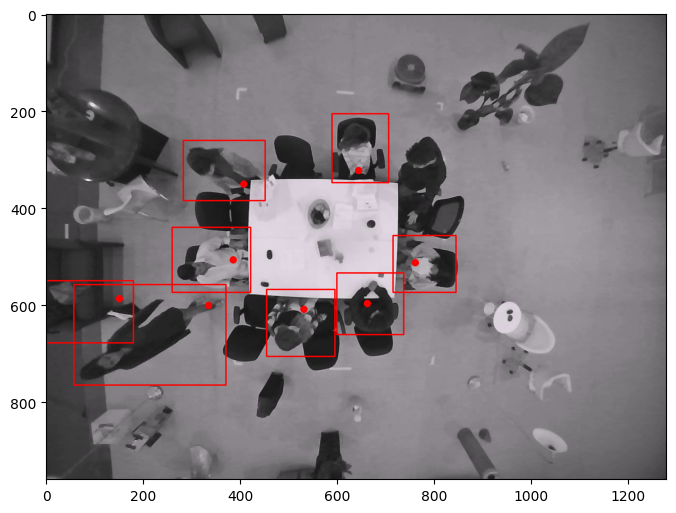

In [10]:
img = cv2.cvtColor(cv2.imread(tst_img_paths[1]), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 256
RATIO = W / ORIGIAL_W
RESIZED_H = int(ORIGINAL_H * RATIO)
IMG_SHAPE = (1, H, W, 3)
TORCH_IMG_SHAPE = (1, 3, H, W)

conf = 0.1
iou = 0.7
agnostic_nms = False
max_det = 300
classes =None
############################

# Initialize the interpreter
interpreter = tf.lite.Interpreter(
  model_path="../../researches/leg_position_detectors/yolov8/run_results/256/weights/best_saved_model/best_full_integer_quant.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

im = np.zeros(IMG_SHAPE, dtype=np.uint8)

resized_img = cv2.resize(img, (W, RESIZED_H))
im[0, :RESIZED_H, :W, :] = resized_img[:, :, :]

details = input_details[0]
interpreter.set_tensor(details['index'], im)
interpreter.invoke()
y = []
for output in output_details:
    x = interpreter.get_tensor(output['index'])
    scale, zero_point = output['quantization']
    x = (x.astype(np.float32) - zero_point) * scale  # re-scale

    # Denormalize xywh by image size. See https://github.com/ultralytics/ultralytics/pull/1695
    # xywh are normalized in TFLite/EdgeTPU to mitigate quantization error of integer models
    x[:, [0, 2]] *= W
    x[:, [1, 3]] *= H
    y.append(x)

y = [x if isinstance(x, np.ndarray) else x.numpy() for x in y]

mcv = float('-inf')
lci = -1
for idx, s in enumerate(y):
    dim_1 = s.shape[1]
    if dim_1 > mcv:
        mcv = dim_1
        lci = idx
y_order = [item for index, item in enumerate(y) if index not in [lci]]
y_decoded = decode_bbox_naive(y_order, TORCH_IMG_SHAPE)

kpt_shape = (y[lci].shape[-1] // 2, 2)
y_kpts_decoded = decode_kpts_naive(y_order,
                            TORCH_IMG_SHAPE,
                            np.transpose(y[lci], (0, 2, 1)),
                            kpt_shape,
                            bs=1)
outputs = np.concatenate([y_decoded, y_kpts_decoded], 1)

outputs = np.transpose(outputs, (0, 2, 1))
rows = outputs.shape[1]
rows

boxes = []
scores = []
class_ids = []
kps = []

# Iterate through output to collect bounding boxes, confidence scores, and class IDs
for i in range(rows):
    classes_scores = outputs[0][i][4:5]
    (minScore, maxScore, minClassLoc, (x, maxClassIndex)) = cv2.minMaxLoc(classes_scores)
    if maxScore >= conf:
        box = [
            outputs[0][i][0] - (0.5 * outputs[0][i][2]),
            outputs[0][i][1] - (0.5 * outputs[0][i][3]),
            outputs[0][i][2],
            outputs[0][i][3],
        ]
        boxes.append(box)
        scores.append(maxScore)
        class_ids.append(maxClassIndex)
        kps.append(outputs[0][i][5:7])

# Apply NMS (Non-maximum suppression)
result_boxes = cv2.dnn.NMSBoxes(boxes, scores, conf, iou, 0.5)

detections = []

# Iterate through NMS results to draw bounding boxes and labels
for i in range(len(result_boxes)):
    index = result_boxes[i]
    box = boxes[index]
    
    detections.append([*box, scores[index], class_ids[index], *kps[index]])
    
detections = np.array(detections)

for box in detections:
    cv2.rectangle(img, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 2)

for p in detections:
    cv2.circle(img, (p[-2:] // RATIO).astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(8, 8))
plt.imshow(img)